# 🎨 Visuals & Graph Styling Boilerplate

**Purpose:** Canonical template and boilerplate for scientific visualization, NetworkX graph topologies, data charts, and design token / colormap palettes conforming to **The Scriber Experience** design system.

🗓️ **Created:** 10-13-2026 | 🪶 **Author:** Scriber Labs

---

## 📋 Agenda

1. **Setup & Theme Configuration** — Imports, dark slate styling, and typography setup
2. **Simple Graphs & Data Visualizations** — Line plots, time series, distributions, and scatter charts
3. **NetworkX Graph Topologies** — Ring, Erdos-Renyi, Small-World, and Complete network diagrams
4. **Multi-Panel Scientific Dashboard** — Layout composition combining time-domain and phase data
5. **Color Palettes & Semantic Colormaps** — Token showcases, comparison swatches, and colormap gradients

## 1️⃣ Setup & Theme Configuration

### 📖 Educational Note
This section initializes the scientific stack and sets the dark slate glassmorphic theme tokens. Plots use high-contrast foregrounds (`#e6edf3`), dark backgrounds (`#0d1117`), card panels (`#161b22`), and vibrant cyan/purple/green accent spectra.

In [10]:

from typing import Final, Dict, List, Tuple

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import networkx as nx
# Standard scientific stack imports
import numpy as np

# Jupyter display magic
%matplotlib inline

# --- 🎭 Design Tokens & Color Constants (The Scriber Experience) ---
THEME_BG: Final[str] = "#0d1117"
CARD_BG: Final[str] = "#161b22"
BORDER_COLOR: Final[str] = "#30363d"
GRID_COLOR: Final[str] = "#21262d"
TEXT_PRIMARY: Final[str] = "#e6edf3"
TEXT_MUTED: Final[str] = "#8b949e"

# Core Palette tokens
PROJECT_COLORS: Final[Dict[str, str]] = {
    "cyan_light": "#00FFEE",
    "cyan_blue": "#00E8FF",
    "blue_light": "#14B5FF",
    "indigo": "#5280FF",
    "purple_light": "#7952F5",
    "purple_deep": "#A855F7",
    "pink_vibrant": "#FF66B3",
    "pink_alt": "#FF40A1",
    "orange_warm": "#FF9D57",
    "orange_soft": "#F78166",
    "green_neon": "#31FF48",
    "green_lime": "#70E000",
    "green_jade": "#00FF7F",
    "yellow_orange": "#FFD166",
}

# Semantic comparison categories
COMPARISON_PALETTE: Final[Dict[str, Dict[str, str]]] = {
    "solvers": {
        "rk45": PROJECT_COLORS["cyan_light"],
        "euler": PROJECT_COLORS["purple_light"],
        "rotor": PROJECT_COLORS["cyan_blue"],
    },
    "topologies": {
        "complete": PROJECT_COLORS["cyan_light"],
        "ring": PROJECT_COLORS["purple_light"],
        "small_world": PROJECT_COLORS["blue_light"],
        "erdos_renyi": PROJECT_COLORS["orange_soft"],
    },
    "metrics": {
        "order_parameter": PROJECT_COLORS["cyan_light"],
        "lie_symmetry": PROJECT_COLORS["green_jade"],
        "fourier": PROJECT_COLORS["orange_warm"],
        "psd": PROJECT_COLORS["purple_deep"],
    }
}

def apply_theme_style() -> None:
    """Configure matplotlib rcParams to enforce The Scriber Experience aesthetic."""
    plt.style.use("dark_background")
    plt.rcParams.update({
        "figure.facecolor": THEME_BG,
        "axes.facecolor": CARD_BG,
        "axes.edgecolor": BORDER_COLOR,
        "axes.labelcolor": TEXT_PRIMARY,
        "axes.grid": True,
        "grid.color": GRID_COLOR,
        "grid.alpha": 0.6,
        "grid.linestyle": "--",
        "xtick.color": TEXT_MUTED,
        "ytick.color": TEXT_MUTED,
        "text.color": TEXT_PRIMARY,
        "font.family": "sans-serif",
        "figure.autolayout": False,
    })

apply_theme_style()
print("✨ Theme configured successfully: Dark slate base with glassmorphic cards and crisp accents.")

✨ Theme configured successfully: Dark slate base with glassmorphic cards and crisp accents.


## 2️⃣ Simple Graphs & Data Visualizations

### 📖 Educational Note
Demonstrates standard line trajectories, bounded metric evolution (e.g. synchronization coherence $r(t) \in [0, 1]$), phase distributions, and scatter plots using consistent typography, glow highlights, and responsive legends.

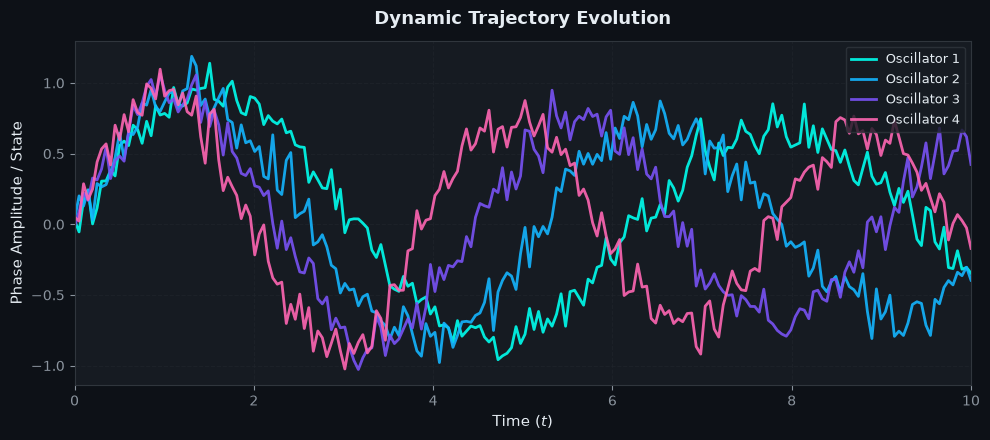

In [11]:
# Set deterministic seed
rng = np.random.default_rng(42)

# Synthesize sample trajectory data
time = np.linspace(0, 10, 200)
n_signals = 4
signals = np.array([
    np.sin(time * (1.0 + 0.2 * i)) * np.exp(-0.05 * time) + 0.1 * rng.normal(size=len(time))
    for i in range(n_signals)
])

colors = [PROJECT_COLORS["cyan_light"], PROJECT_COLORS["blue_light"], PROJECT_COLORS["purple_light"], PROJECT_COLORS["pink_vibrant"]]
labels = [f"Oscillator {i+1}" for i in range(n_signals)]

# Create Time Series Plot
fig, ax = plt.subplots(figsize=(10, 4.5))
for i in range(n_signals):
    ax.plot(time, signals[i], label=labels[i], color=colors[i], linewidth=2.0, alpha=0.9)

ax.set_title("Dynamic Trajectory Evolution", fontsize=13, fontweight="bold", pad=12, color=TEXT_PRIMARY)
ax.set_xlabel("Time ($t$)", fontsize=11, color=TEXT_PRIMARY)
ax.set_ylabel("Phase Amplitude / State", fontsize=11, color=TEXT_PRIMARY)
ax.legend(loc="upper right", facecolor=CARD_BG, edgecolor=BORDER_COLOR, fontsize=9)
ax.set_xlim(0, 10)
plt.tight_layout()
plt.show()

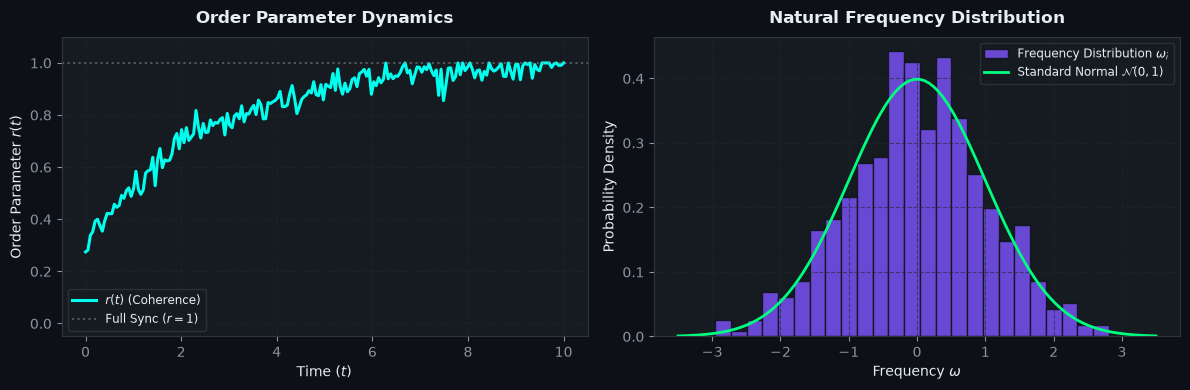

In [12]:
# Synthesize Bounded Metric & Distribution Plot
order_param = 1.0 - 0.7 * np.exp(-0.4 * time) + 0.03 * rng.normal(size=len(time))
order_param = np.clip(order_param, 0.0, 1.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Left: Order Parameter Evolution
ax1.plot(time, order_param, color=PROJECT_COLORS["cyan_light"], linewidth=2.2, label="$r(t)$ (Coherence)")
ax1.axhline(1.0, color=TEXT_MUTED, linestyle=":", alpha=0.5, label="Full Sync ($r=1$)")
ax1.set_title("Order Parameter Dynamics", fontsize=12, fontweight="bold", pad=10)
ax1.set_xlabel("Time ($t$)", fontsize=10)
ax1.set_ylabel("Order Parameter $r(t)$", fontsize=10)
ax1.set_ylim(-0.05, 1.1)
ax1.legend(facecolor=CARD_BG, edgecolor=BORDER_COLOR, fontsize=8.5)

# Right: Distribution Histogram
samples = rng.normal(loc=0.0, scale=1.0, size=500)
n_bins, bins, patches = ax2.hist(
    samples, bins=25, density=True, color=PROJECT_COLORS["purple_light"], 
    edgecolor=THEME_BG, alpha=0.85, label="Frequency Distribution $\\omega_i$"
)
x_fit = np.linspace(-3.5, 3.5, 100)
ax2.plot(x_fit, 1.0 / np.sqrt(2 * np.pi) * np.exp(-0.5 * x_fit**2), color=PROJECT_COLORS["green_jade"], linewidth=2.0, label="Standard Normal $\\mathcal{N}(0, 1)$")
ax2.set_title("Natural Frequency Distribution", fontsize=12, fontweight="bold", pad=10)
ax2.set_xlabel("Frequency $\\omega$", fontsize=10)
ax2.set_ylabel("Probability Density", fontsize=10)
ax2.legend(facecolor=CARD_BG, edgecolor=BORDER_COLOR, fontsize=8.5)

plt.tight_layout()
plt.show()

## 3️⃣ NetworkX Graph Topologies

### 📖 Educational Note
Complex network topologies govern oscillator coupling. This section renders four fundamental network structures:
- **Ring Lattice:** Local 1D nearest-neighbor coupling
- **Watts-Strogatz Small-World:** High local clustering with short characteristic path length
- **Erdős-Rényi Random Graph:** Stochastic uniform edge assignment
- **Complete Graph:** All-to-all mean-field coupling

Nodes and edges use glow-friendly tokens from `PROJECT_COLORS`.

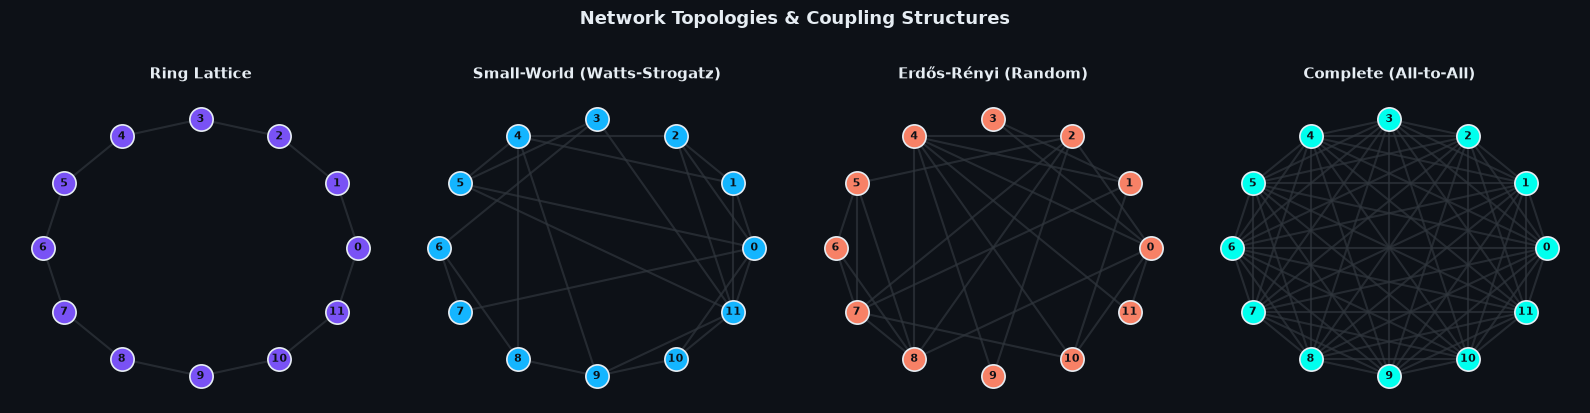

In [13]:
# Generate 4 standard network topologies
n_nodes = 12
graphs: Dict[str, Tuple[nx.Graph, str, str]] = {
    "Ring Lattice": (
        nx.cycle_graph(n_nodes),
        "ring",
        COMPARISON_PALETTE["topologies"]["ring"]
    ),
    "Small-World (Watts-Strogatz)": (
        nx.watts_strogatz_graph(n=n_nodes, k=4, p=0.3, seed=42),
        "small_world",
        COMPARISON_PALETTE["topologies"]["small_world"]
    ),
    "Erdős-Rényi (Random)": (
        nx.erdos_renyi_graph(n=n_nodes, p=0.35, seed=42),
        "erdos_renyi",
        COMPARISON_PALETTE["topologies"]["erdos_renyi"]
    ),
    "Complete (All-to-All)": (
        nx.complete_graph(n_nodes),
        "complete",
        COMPARISON_PALETTE["topologies"]["complete"]
    ),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
axes = axes.flatten()

for idx, (title, (G, topo_key, node_color)) in enumerate(graphs.items()):
    ax = axes[idx]
    ax.set_facecolor(CARD_BG)
    
    # Compute circular layout for crisp visual alignment
    pos = nx.circular_layout(G)
    
    # Draw edges
    nx.draw_networkx_edges(
        G, pos, ax=ax,
        edge_color=BORDER_COLOR,
        width=1.5,
        alpha=0.7
    )
    
    # Draw nodes
    nx.draw_networkx_nodes(
        G, pos, ax=ax,
        node_color=node_color,
        node_size=280,
        edgecolors=TEXT_PRIMARY,
        linewidths=1.2
    )
    
    # Draw node labels
    nx.draw_networkx_labels(
        G, pos, ax=ax,
        font_size=8,
        font_color=THEME_BG,
        font_weight="bold"
    )
    
    ax.set_title(title, fontsize=10.5, fontweight="bold", pad=10, color=TEXT_PRIMARY)
    ax.axis("off")

plt.suptitle("Network Topologies & Coupling Structures", fontsize=13, fontweight="bold", y=1.02, color=TEXT_PRIMARY)
plt.tight_layout()
plt.show()

## 4️⃣ Multi-Panel Scientific Dashboard

### 📖 Educational Note
Combining multiple subplots (Network structure, phase distribution, time trajectories, order parameter) into a cohesive publication-grade layout with balanced spacing.

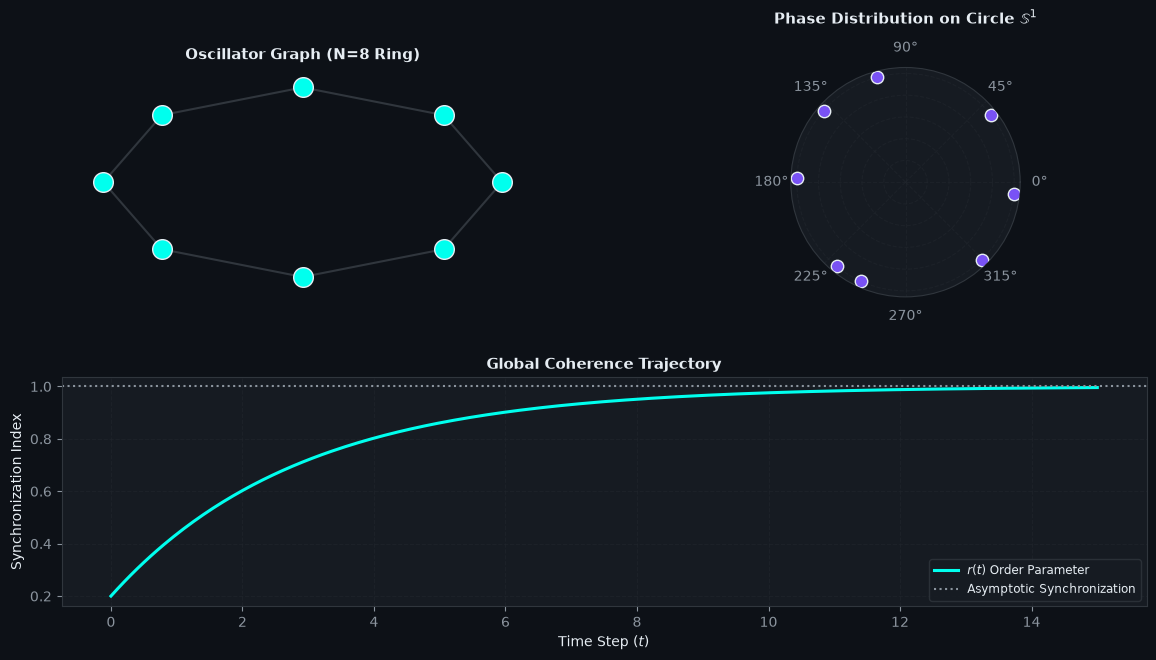

In [14]:
fig = plt.figure(figsize=(14, 7))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.25)

ax_top_left = fig.add_subplot(gs[0, 0])
ax_top_right = fig.add_subplot(gs[0, 1])
ax_bottom = fig.add_subplot(gs[1, :])

# 1. Graph Layout in Top Left
G_sub = nx.cycle_graph(8)
pos_sub = nx.circular_layout(G_sub)
nx.draw_networkx_edges(G_sub, pos_sub, ax=ax_top_left, edge_color=BORDER_COLOR, width=1.5)
nx.draw_networkx_nodes(G_sub, pos_sub, ax=ax_top_left, node_color=PROJECT_COLORS["cyan_light"], node_size=200, edgecolors=TEXT_PRIMARY)
ax_top_left.set_title("Oscillator Graph (N=8 Ring)", fontsize=11, fontweight="bold", color=TEXT_PRIMARY)
ax_top_left.axis("off")

# 2. Phase Circle (Polar representation) in Top Right
phases_sample = np.linspace(0, 2*np.pi, 8, endpoint=False) + rng.normal(0, 0.2, 8)
ax_top_right.remove()  # Replace with polar subplot
ax_polar = fig.add_subplot(gs[0, 1], projection='polar')
ax_polar.set_facecolor(CARD_BG)
ax_polar.scatter(phases_sample, np.ones_like(phases_sample), color=PROJECT_COLORS["purple_light"], s=80, edgecolors=TEXT_PRIMARY, zorder=5)
ax_polar.set_yticklabels([])
ax_polar.set_title("Phase Distribution on Circle $\\mathbb{S}^1$", fontsize=11, fontweight="bold", pad=12, color=TEXT_PRIMARY)

# 3. Time Series & Order Parameter Dynamics on Bottom
t_axis = np.linspace(0, 15, 300)
r_dynamics = 1.0 - 0.8 * np.exp(-0.35 * t_axis)
ax_bottom.plot(t_axis, r_dynamics, color=PROJECT_COLORS["cyan_light"], linewidth=2.2, label="$r(t)$ Order Parameter")
ax_bottom.axhline(1.0, color=TEXT_MUTED, linestyle=":", label="Asymptotic Synchronization")
ax_bottom.set_title("Global Coherence Trajectory", fontsize=11, fontweight="bold", color=TEXT_PRIMARY)
ax_bottom.set_xlabel("Time Step ($t$)", fontsize=10)
ax_bottom.set_ylabel("Synchronization Index", fontsize=10)
ax_bottom.legend(facecolor=CARD_BG, edgecolor=BORDER_COLOR, fontsize=8.5, loc="lower right")

plt.show()

## 5️⃣ Color Palettes & Semantic Colormaps

### 📖 Educational Note
This section showcases all design tokens, categorical comparison swatches, and continuous colormaps available in the palette.

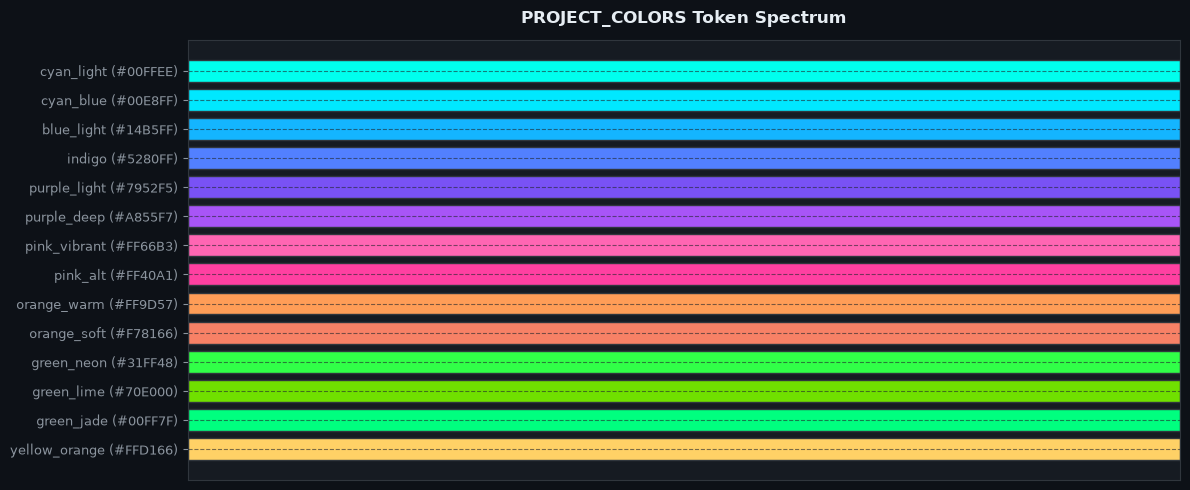

In [15]:
# Render all project color tokens
token_names = list(PROJECT_COLORS.keys())
token_hexes = list(PROJECT_COLORS.values())
n_tokens = len(token_names)

fig, ax = plt.subplots(figsize=(12, 5))
y_positions = np.arange(n_tokens)

ax.barh(y_positions, np.ones(n_tokens), color=token_hexes, edgecolor=BORDER_COLOR, height=0.75)
ax.set_yticks(y_positions)
ax.set_yticklabels([f"{name} ({hex_val})" for name, hex_val in zip(token_names, token_hexes)], fontsize=9)
ax.set_xlim(0, 1)
ax.set_xticks([])
ax.invert_yaxis()
ax.set_title("PROJECT_COLORS Token Spectrum", fontsize=12, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

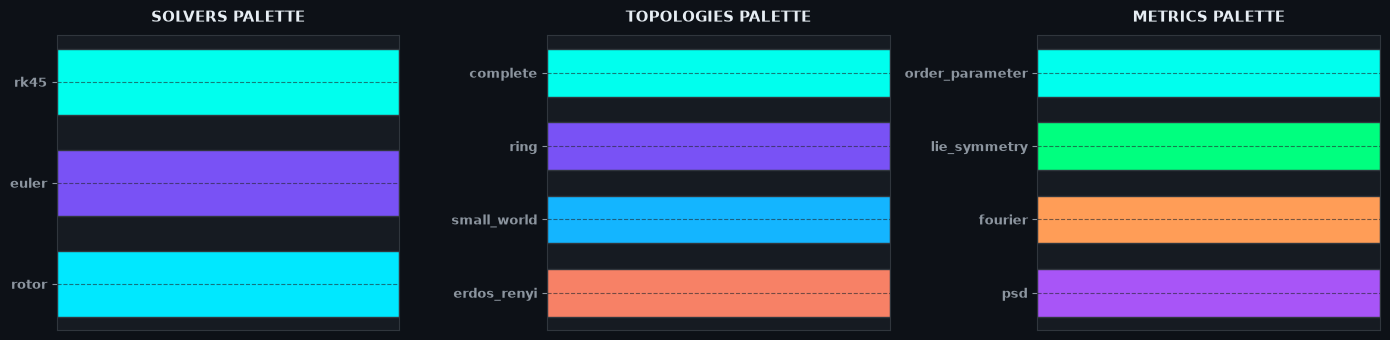

In [16]:
# Render comparison palettes
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

for idx, (cat_name, cat_dict) in enumerate(COMPARISON_PALETTE.items()):
    ax = axes[idx]
    keys = list(cat_dict.keys())
    colors_list = list(cat_dict.values())
    y_pos = np.arange(len(keys))
    
    ax.barh(y_pos, np.ones(len(keys)), color=colors_list, edgecolor=BORDER_COLOR, height=0.65)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(keys, fontsize=9.5, fontweight="bold")
    ax.set_xlim(0, 1)
    ax.set_xticks([])
    ax.invert_yaxis()
    ax.set_title(f"{cat_name.upper()} PALETTE", fontsize=11, fontweight="bold", pad=10)

plt.tight_layout()
plt.show()

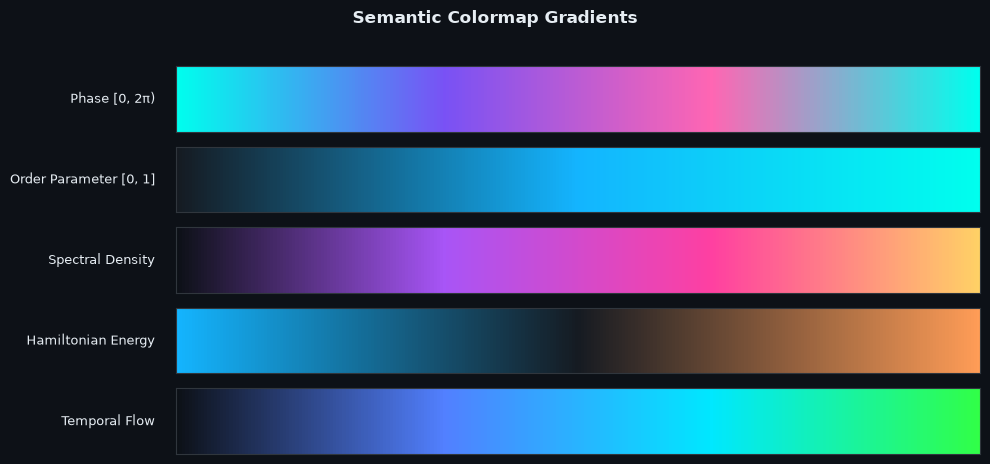

🎉 Visuals & Graph Styling Boilerplate execution complete.


In [17]:
# Define and display semantic colormaps
def create_linear_colormap(name: str, colors: List[str]) -> mcolors.LinearSegmentedColormap:
    """Create a smooth linear segmented colormap from a sequence of hex colors."""
    return mcolors.LinearSegmentedColormap.from_list(name, colors, N=256)

colormaps: Dict[str, mcolors.LinearSegmentedColormap] = {
    "Phase [0, 2π)": create_linear_colormap("phase_cmap", [PROJECT_COLORS["cyan_light"], PROJECT_COLORS["purple_light"], PROJECT_COLORS["pink_vibrant"], PROJECT_COLORS["cyan_light"]]),
    "Order Parameter [0, 1]": create_linear_colormap("order_param_cmap", [CARD_BG, PROJECT_COLORS["blue_light"], PROJECT_COLORS["cyan_light"]]),
    "Spectral Density": create_linear_colormap("spectral_cmap", [THEME_BG, PROJECT_COLORS["purple_deep"], PROJECT_COLORS["pink_alt"], PROJECT_COLORS["yellow_orange"]]),
    "Hamiltonian Energy": create_linear_colormap("hamiltonian_cmap", [PROJECT_COLORS["blue_light"], CARD_BG, PROJECT_COLORS["orange_warm"]]),
    "Temporal Flow": create_linear_colormap("temporal_cmap", [THEME_BG, PROJECT_COLORS["indigo"], PROJECT_COLORS["cyan_blue"], PROJECT_COLORS["green_neon"]]),
}

fig, axes = plt.subplots(len(colormaps), 1, figsize=(10, 4.5))
gradient = np.linspace(0, 1, 256).reshape(1, -1)

for idx, (cmap_name, cmap_obj) in enumerate(colormaps.items()):
    ax = axes[idx]
    ax.imshow(gradient, aspect="auto", cmap=cmap_obj)
    ax.set_yticks([])
    ax.set_xticks([])
    ax.set_ylabel(cmap_name, rotation=0, ha="right", va="center", fontsize=9, color=TEXT_PRIMARY, labelpad=15)

plt.suptitle("Semantic Colormap Gradients", fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print("🎉 Visuals & Graph Styling Boilerplate execution complete.")
